In [8]:
import astropy.coordinates as coord
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
from scipy.interpolate import RegularGridInterpolator

In [21]:
t = Table.read("../data/final_sample_zsun0_zgrbits45.fits")
cells = Table.read("../data/final_sample_zsun0_zgrbits45_cells.ecsv")

In [ ]:
# A_G/E values from the ZGR extinction curve
E_grid = np.array([0.01, 0.5, 1.0, 2.0, 3.0])
Teff_grid = np.array([4000, 4500, 5000])
RG_grid = np.array(
    [
        [2.232, 2.134, 2.050, 1.921, 1.825],
        [2.322, 2.211, 2.118, 1.974, 1.868],
        [2.401, 2.279, 2.177, 2.020, 1.905],
    ]
)
RG = RegularGridInterpolator(
    (Teff_grid, E_grid), RG_grid, bounds_error=False, fill_value=None
)

E = t["zgr_e"]
teff = np.clip(t["teff"], 4000, 5000)  # force within grid range
A_G = RG(np.column_stack([teff, E])) * E

In [20]:
(A_G < 1.0).sum() / len(A_G)

np.float64(0.5584412055815398)

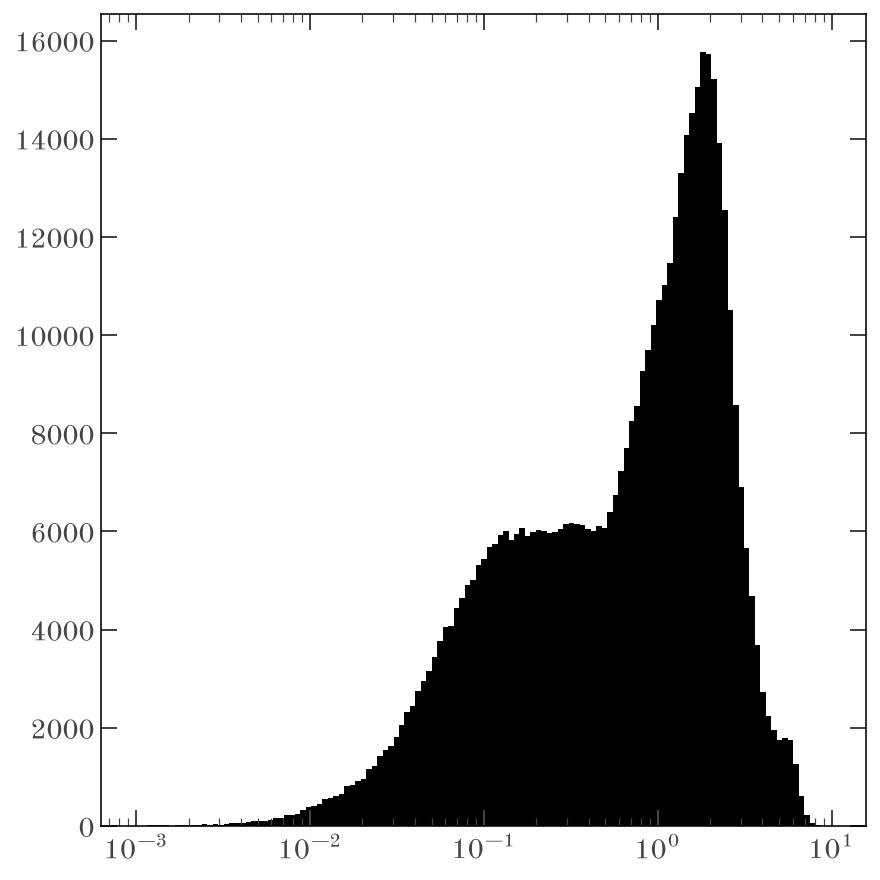

In [18]:
plt.hist(A_G, bins=np.geomspace(1e-3, 10, 128))
plt.xscale("log")

In [ ]:
DM = 5 * np.log10(1000 / t["zgr_plx"]) - 5  # distance modulus
G = t["g_mag"]
G_lim = 17.5  # Gaia DR3 XP spectra cutoff

In [34]:
def assign(cells, R, phi):
    """cell_id of each star, or -1 for stars outside every cell."""
    R = np.asarray(R, float)
    phi = np.mod(np.asarray(phi, float), 2 * np.pi)
    cell_id = np.full(len(R), -1)
    for c in cells:
        inside = (
            (R >= c["R_lo"])
            & (R < c["R_hi"])
            & (phi >= c["phi_lo"])
            & (phi < c["phi_hi"])
        )
        cell_id[inside] = c["cell_id"]
    return cell_id

In [35]:
cell_ids = assign(cells, t["R_gc_kpc"], t["phi_gc_rad"])

In [39]:
cell_keep = np.zeros(len(t), bool)
for cell_id in np.unique(cell_ids):
    if cell_id == -1:
        continue

    cell_mask = (cell_ids == cell_id)

    # subset of table in a given spatial cell
    cell_t = t[cell_mask]
    DM_max = np.percentile(DM[cell_mask], 95)
    A_max = np.percentile(A_G[cell_mask], 95)

    # apparent mag for worst-case extinction and distance in cell
    G_worst = G[cell_mask] + (DM_max - DM[cell_mask]) + (A_max - A_G[cell_mask])
    cell_keep[cell_mask] = G_worst < G_lim

In [40]:
cell_keep.sum() / len(cell_keep)

np.float64(0.8767442311797699)